# 2장 3강: 코호트 기반 리텐션 분석과 세그멘테이션 — 실습문제

## 실습 목표

- 분석 목적에 맞는 코호트 기준을 설정할 수 있다.
- 첫 유효 기능 사용 월을 기준으로 월간 코호트를 만들 수 있다.
- 코호트별 N개월 리텐션 테이블과 히트맵을 생성할 수 있다.
- 코호트와 세그먼트를 교차하여 그룹별 유지 패턴을 비교할 수 있다.
- 리텐션 차이를 근거로 개선 대상을 찾고 추가 분석 방향을 제안할 수 있다.

## 실습 환경 / 데이터

- Python
- pandas
- matplotlib
- `ravenstack_subscriptions.csv`
- `ravenstack_feature_usage.csv`

Ravenstack은 구독형 B2B SaaS입니다. 이번 실습의 분석 질문은 다음과 같습니다.

> 제품 기능을 처음 사용한 구독이 이후 달에도 다시 기능을 사용하는가?

따라서 코호트 기준은 가입일이나 구독 시작일이 아니라 **첫 유효 기능 사용 월**로 설정합니다.

이번 실습에서 유효 기능 사용은 다음 조건을 모두 만족하는 기록입니다.

- `usage_date >= start_date`
- 종료일이 없거나 `usage_date <= end_date`

> 이번 실습의 월간 N개월 리텐션은 첫 유효 기능 사용 월로부터 정확히 N개월 뒤에 다시 기능을 사용한 구독의 비율입니다.

## 실습 준비

1. 필요한 라이브러리를 불러오세요.
2. 두 CSV 파일을 각각 `subscriptions`, `feature_usage`에 불러오세요.
3. 각 데이터의 행과 열 개수, 상위 5개 행을 확인하세요.
4. 분석 대상 컬럼의 자료형과 결측치 개수를 확인하세요.
5. `start_date`, `end_date`, `usage_date`를 날짜형으로 변환하세요.
6. 기능 사용 데이터와 구독 데이터를 `subscription_id`로 결합하여 `usage_with_sub`을 만드세요.
7. 구독 시작 전 사용 기록과 구독 종료 후 사용 기록의 개수를 확인하세요.
8. 유효 기능 사용 조건을 적용한 `valid_usage`를 만드세요.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 한글 폰트 설정
for name in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
    if name in {f.name for f in fm.fontManager.ttflist}:
        plt.rcParams['font.family'] = name
        break
plt.rcParams['axes.unicode_minus'] = False

# 1~2. 데이터 불러오기
subscriptions = pd.read_csv('ravenstack_subscriptions.csv')
feature_usage = pd.read_csv('ravenstack_feature_usage.csv')

# 3. 크기와 상위 5행
print('subscriptions:', subscriptions.shape)
display(subscriptions.head())
print('feature_usage:', feature_usage.shape)
display(feature_usage.head())

# 4. 분석 대상 컬럼의 자료형과 결측치
sub_cols = ['subscription_id', 'start_date', 'end_date', 'plan_tier', 'billing_frequency']
use_cols = ['usage_id', 'subscription_id', 'usage_date']
display(pd.DataFrame({'dtype': subscriptions[sub_cols].dtypes, 'null_count': subscriptions[sub_cols].isna().sum()}))
display(pd.DataFrame({'dtype': feature_usage[use_cols].dtypes, 'null_count': feature_usage[use_cols].isna().sum()}))

# 5. 날짜형 변환
subscriptions['start_date'] = pd.to_datetime(subscriptions['start_date'])
subscriptions['end_date'] = pd.to_datetime(subscriptions['end_date'])
feature_usage['usage_date'] = pd.to_datetime(feature_usage['usage_date'])

# 6. 결합 (기능 사용 기록 기준 left join)
usage_with_sub = feature_usage.merge(
    subscriptions[['subscription_id', 'start_date', 'end_date', 'plan_tier', 'billing_frequency']],
    on='subscription_id', how='left')
print('usage_with_sub:', usage_with_sub.shape, '| 구독 정보 매칭 실패:', usage_with_sub['start_date'].isna().sum())

# 7. 구독 기간 밖의 사용 기록
before_start = usage_with_sub['usage_date'] < usage_with_sub['start_date']
after_end = usage_with_sub['end_date'].notna() & (usage_with_sub['usage_date'] > usage_with_sub['end_date'])
print('구독 시작 전 사용 기록:', before_start.sum())
print('구독 종료 후 사용 기록:', after_end.sum())

# 8. 유효 기능 사용
valid_usage = usage_with_sub[~before_start & ~after_end].copy()
print('valid_usage:', len(valid_usage), '행 | 고유 구독', valid_usage['subscription_id'].nunique(), '개')
print('유효 사용 기간:', valid_usage['usage_date'].min().date(), '~', valid_usage['usage_date'].max().date())

subscriptions: (5000, 14)


,subscription_id,account_id,start_date,end_date,plan_tier,seats,mrr_amount,arr_amount,is_trial,upgrade_flag,downgrade_flag,churn_flag,billing_frequency,auto_renew_flag
0,S-8cec59,A-3c1a3f,2023-12-23,2024-04-12,Enterprise,14,2786,33432,False,False,False,True,monthly,True
1,S-0f6f44,A-9b9fe9,2024-06-11,NaN,Pro,17,833,9996,False,False,False,False,monthly,True
2,S-51c0d1,A-659280,2024-11-25,NaN,Enterprise,62,0,0,True,True,False,False,annual,False
3,S-f81687,A-e7a1e2,2024-11-23,2024-12-13,Enterprise,5,995,11940,False,False,False,True,monthly,True
4,S-cff5a2,A-ba6516,2024-01-10,NaN,Enterprise,27,5373,64476,False,False,False,False,monthly,True


feature_usage: (25000, 8)


,usage_id,subscription_id,usage_date,feature_name,usage_count,usage_duration_secs,error_count,is_beta_feature
0,U-1c6c24,S-0fcf7d,2023-07-27,feature_20,9,5004,0,False
1,U-f07cb8,S-c25263,2023-08-07,feature_5,9,369,0,False
2,U-096807,S-f29e7f,2023-12-07,feature_3,9,1458,0,False
3,U-6b1580,S-be655e,2024-07-28,feature_40,5,2085,0,False
4,U-720a29,S-f9b1d0,2024-12-02,feature_12,12,900,0,False


,dtype,null_count
subscription_id,str,0
start_date,str,0
end_date,str,4514
plan_tier,str,0
billing_frequency,str,0


,dtype,null_count
usage_id,str,0
subscription_id,str,0
usage_date,str,0


usage_with_sub: (25000, 12) | 구독 정보 매칭 실패: 0
구독 시작 전 사용 기록: 19142
구독 종료 후 사용 기록: 290
valid_usage: 5568 행 | 고유 구독 2651 개
유효 사용 기간: 2023-02-15 ~ 2024-12-31


> **데이터 품질 메모**: 전체 25,000건 중 **구독 시작 전 기록이 19,142건(76.6%)**, 종료 후 기록이 290건으로, 유효 기능 사용은 5,568건(고유 구독 2,651개)만 남습니다. 구독 기간 밖의 기록을 그대로 쓰면 "구독하지 않은 상태의 사용"까지 리텐션으로 잡혀 결과가 왜곡되므로 걸러내야 합니다. 다만 제외 비율이 매우 높다는 점은 이후 해석에서도 한계로 염두에 두어야 합니다(합성 데이터 특성이거나, 실무라면 날짜 기록 방식·구독 갱신 이력 등을 점검해야 할 수준).

---

## 필수 1. 월별 코호트 리텐션 테이블 만들기

### 문제 1-1. 첫 기능 사용 이후에도 다시 제품을 사용하는가?

#### 문제 설명

각 구독의 첫 유효 기능 사용 월을 코호트로 설정하고, 이후 월별로 다시 기능을 사용한 구독의 비율을 계산하세요.

이번 문제에서는 2024년 1월부터 6월까지 시작한 코호트와 `Month 0`부터 `Month 6`까지의 리텐션을 확인합니다.

#### 요구사항

1. `valid_usage`에 기능 사용 월을 나타내는 `activity_month`를 만드세요.
2. 구독별 첫 `activity_month`를 구해 `cohort_month`로 추가하세요.
3. `activity_month - cohort_month`를 개월 수로 계산하여 `month_index`를 만드세요.
4. 코호트별 최초 구독 수를 `cohort_sizes`로 계산하세요.
5. `cohort_month`와 `month_index`별 고유 구독 수를 집계하세요.
6. 고유 구독 수를 `cohort_sizes`로 나누어 `retention_table`을 만드세요.
7. 2024년 1월~6월 코호트와 Month 0~6을 선택하여 백분율 표로 출력하세요.
8. 선택한 리텐션 테이블을 히트맵으로 시각화하세요.
9. 1월~6월 코호트 중 Month 1 리텐션이 가장 높은 코호트와 가장 낮은 코호트를 찾으세요.

#### 해석 질문

**Q1.** 이번 분석에서 첫 기능 사용 월을 코호트 기준으로 선택한 이유는 무엇인가요?  
**Q2.** Month 0 리텐션이 모두 100%인 이유는 무엇인가요?  
**Q3.** Month 1 리텐션이 가장 높은 코호트와 가장 낮은 코호트는 어디인가요?  
**Q4.** N개월 리텐션이 앞선 달보다 높아질 수도 있나요?

#### 제출 결과

- 코호트 및 `month_index` 생성 코드
- 월별 리텐션 테이블
- 리텐션 히트맵
- Month 1 리텐션 비교
- Q1~Q4 답변

,cohort_size,Month 0,Month 1,Month 2,Month 3,Month 4,Month 5,Month 6
2024-01,73,100.0,15.1,16.4,19.2,20.5,16.4,19.2
2024-02,89,100.0,21.3,16.9,15.7,7.9,23.6,28.1
2024-03,107,100.0,22.4,22.4,20.6,19.6,10.3,21.5
2024-04,106,100.0,17.9,27.4,19.8,19.8,16.0,15.1
2024-05,137,100.0,18.2,19.7,16.8,21.2,19.7,15.3
2024-06,150,100.0,28.0,12.0,16.0,20.0,15.3,21.3


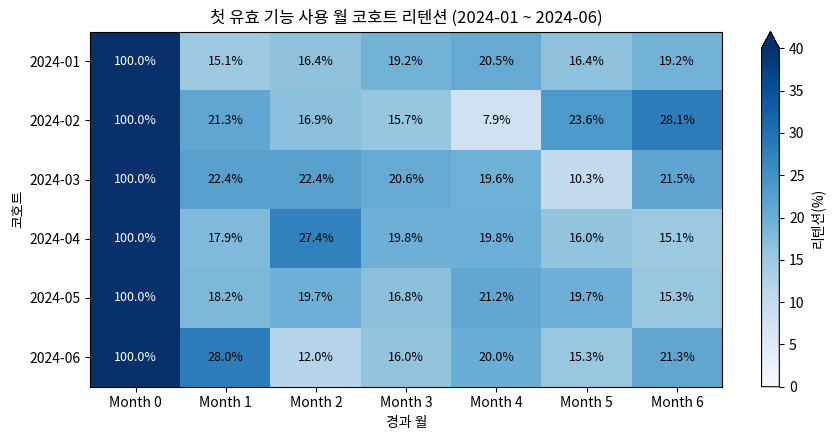

Month 1 최고: 2024-06 (28.0%) | 최저: 2024-01 (15.1%)


In [2]:
# 1. 기능 사용 월
valid_usage['activity_month'] = valid_usage['usage_date'].dt.to_period('M')

# 2. 구독별 첫 사용 월 = 코호트
valid_usage['cohort_month'] = valid_usage.groupby('subscription_id')['activity_month'].transform('min')

# 3. 경과 개월 수 (Period 차이 → 개월 수)
valid_usage['month_index'] = (
    (valid_usage['activity_month'].dt.year - valid_usage['cohort_month'].dt.year) * 12
    + (valid_usage['activity_month'].dt.month - valid_usage['cohort_month'].dt.month)
)

# 4. 코호트 크기
cohort_sizes = valid_usage.groupby('cohort_month')['subscription_id'].nunique()

# 5. 코호트 × 경과 월별 고유 구독 수
cohort_counts = (valid_usage.groupby(['cohort_month', 'month_index'])['subscription_id']
                 .nunique().unstack(fill_value=0))

# 6. 리텐션 테이블
retention_table = cohort_counts.div(cohort_sizes, axis=0)

# 관찰 가능 여부 확인: 데이터 마지막 월 이후 칸은 NaN 처리 (0과 구분)
last_month = valid_usage['activity_month'].max()
for cm in retention_table.index:
    for mi in retention_table.columns:
        if cm + mi > last_month:
            retention_table.loc[cm, mi] = float('nan')

# 7. 2024-01 ~ 2024-06 코호트, Month 0~6
sel_cohorts = pd.period_range('2024-01', '2024-06', freq='M')
selected_retention = retention_table.loc[sel_cohorts, range(0, 7)]
selected_retention.columns = [f'Month {i}' for i in selected_retention.columns]
display(pd.concat([cohort_sizes.loc[sel_cohorts].rename('cohort_size'), (selected_retention * 100).round(1)], axis=1))

# 8. 히트맵
fig, ax = plt.subplots(figsize=(9, 4.5))
data = selected_retention.values * 100
im = ax.imshow(data, cmap='Blues', aspect='auto', vmin=0, vmax=40)
ax.set_xticks(range(data.shape[1])); ax.set_xticklabels(selected_retention.columns)
ax.set_yticks(range(data.shape[0])); ax.set_yticklabels([str(c) for c in sel_cohorts])
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        v = data[i, j]
        ax.text(j, i, f'{v:.1f}%', ha='center', va='center', fontsize=9,
                color='white' if v > 30 else 'black')
ax.set_title('첫 유효 기능 사용 월 코호트 리텐션 (2024-01 ~ 2024-06)')
ax.set_xlabel('경과 월'); ax.set_ylabel('코호트')
fig.colorbar(im, ax=ax, label='리텐션(%)', extend='max')
plt.tight_layout(); plt.show()

# 9. Month 1 최고/최저 코호트
m1_ret = selected_retention['Month 1']
print(f'Month 1 최고: {m1_ret.idxmax()} ({m1_ret.max():.1%}) | 최저: {m1_ret.idxmin()} ({m1_ret.min():.1%})')

### 필수 1 답변 작성란

**Month 1 비교**: 1~6월 코호트 중 Month 1 리텐션 최고는 **2024-06 (28.0%)**, 최저는 **2024-01 (15.1%)**입니다. 전반적으로 첫 사용 다음 달에 다시 기능을 쓰는 구독은 15~28% 수준으로, 첫 달 이후 대부분이 재사용하지 않습니다.

- **Q1.** 분석 질문이 "기능을 **처음 사용한** 구독이 이후에도 **다시 사용하는가**"이기 때문입니다. 구독 시작일을 기준으로 하면 시작 후 한참 뒤에 처음 쓴 구독, 아예 쓰지 않은 구독이 섞여 "제품 경험 이후의 재사용"을 측정할 수 없습니다. 코호트의 출발점은 측정하려는 행동(첫 유효 기능 사용)과 일치해야 합니다.
- **Q2.** 코호트 자체가 "그 달에 첫 유효 기능 사용을 한 구독"으로 정의되므로, Month 0에는 코호트의 모든 구독이 정의상 활동한 상태입니다. 즉 Month 0 분자 = 분모 = 코호트 크기라 항상 100%입니다.
- **Q3.** 가장 높은 코호트는 **2024-06 (28.0%)**, 가장 낮은 코호트는 **2024-01 (15.1%)**입니다. 두 코호트의 차이는 약 12.9%p입니다. 다만 코호트 크기가 73~150개로 작아서 몇 건만 달라도 수 %p씩 움직인다는 점을 고려해야 합니다.
- **Q4.** 네, 높아질 수 있습니다. 이번 리텐션은 "정확히 N개월 뒤에 사용했는가"(N-day형 월간 리텐션)라서, 중간 달에 쉬었다가 다시 돌아온 구독도 해당 월에 포함됩니다. 실제로 2024-04 코호트는 Month 1 17.9% → Month 2 27.4%, 2024-02 코호트는 Month 4 7.9% → Month 6 28.1%로 올라갑니다. 반면 "N개월 이후까지 계속 남아 있는가"를 보는 unbounded/rolling 리텐션은 정의상 감소만 합니다.

---

## 필수 2. 요금제별 Month 1 리텐션 비교하기

### 문제 2-1. 어떤 요금제의 초기 유지율이 상대적으로 낮은가?

#### 문제 설명

2024년 1월부터 6월까지 첫 기능 사용을 시작한 구독을 대상으로 요금제별 Month 1 리텐션을 비교하세요.

이 문제는 **코호트 기준과 속성 기반 세그먼트인 `plan_tier`를 교차하여 분석**하는 문제입니다.

#### 요구사항

1. 구독별 `cohort_month`, `plan_tier`를 한 행으로 정리한 `cohort_base`를 만드세요.
2. 2024년 1월~6월 코호트만 `selected_base`에 저장하세요.
3. 요금제별 코호트 구독 수를 계산하세요.
4. `month_index == 1`인 기록을 이용해 요금제별 Month 1 재사용 구독 수를 계산하세요.
5. 두 값을 나누어 `plan_retention`을 만드세요.
6. Month 1 리텐션이 낮은 순서로 정렬하고 백분율로 출력하세요.
7. 요금제별 Month 1 리텐션을 막대그래프로 시각화하세요.
8. 가장 낮은 요금제를 찾아 개선 방향과 추가 확인 데이터를 제안하세요.

#### 해석 질문

**Q1.** 이 분석에서 `plan_tier`는 어떤 세그멘테이션 기준인가요?  
**Q2.** Month 1 리텐션이 가장 낮은 요금제는 무엇인가요?  
**Q3.** 전체 리텐션만 보는 것보다 요금제별로 나누어 보는 것이 유용한 이유는 무엇인가요?  
**Q4.** 요금제별 차이만으로 낮은 리텐션의 원인을 확정할 수 있나요?

#### 제출 결과

- `cohort_base`와 `selected_base`
- `plan_retention` 결과
- 요금제별 리텐션 그래프
- 개선 방향과 추가 확인 데이터
- Q1~Q4 답변

selected_base: 662 개 구독


,cohort_subs,month1_subs,month1_retention
plan_tier,,,
Basic,223,42,18.8%
Pro,219,48,21.9%
Enterprise,220,50,22.7%


전체(1~6월 코호트) Month 1 리텐션: 21.1%


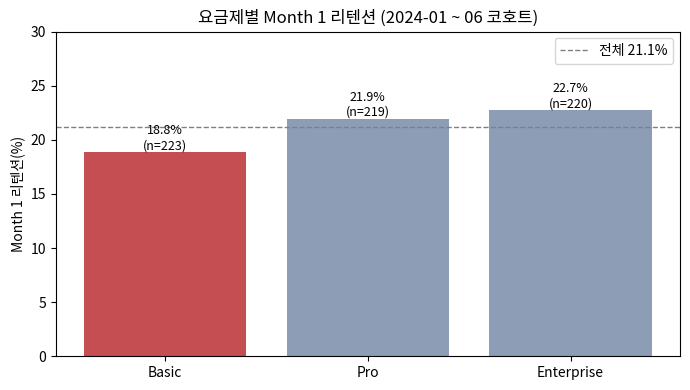

최저 요금제: Basic (18.8%), 최고와 격차 3.9%p


In [3]:
# 1. 구독별 코호트·요금제 (한 구독 = 한 행)
cohort_base = (valid_usage[['subscription_id', 'cohort_month', 'plan_tier', 'billing_frequency']]
               .drop_duplicates('subscription_id').reset_index(drop=True))

# 2. 2024-01 ~ 2024-06 코호트
selected_base = cohort_base[cohort_base['cohort_month'].isin(sel_cohorts)].copy()
print('selected_base:', len(selected_base), '개 구독')

# 3. 요금제별 코호트 구독 수
plan_size = selected_base.groupby('plan_tier')['subscription_id'].nunique()

# 4. 요금제별 Month 1 재사용 구독 수
m1_ids = valid_usage.loc[valid_usage['month_index'] == 1, 'subscription_id'].unique()
plan_m1 = selected_base[selected_base['subscription_id'].isin(m1_ids)].groupby('plan_tier')['subscription_id'].nunique()

# 5~6. plan_retention
plan_retention = pd.DataFrame({'cohort_subs': plan_size, 'month1_subs': plan_m1})
plan_retention['month1_retention'] = plan_retention['month1_subs'] / plan_retention['cohort_subs']
plan_retention = plan_retention.sort_values('month1_retention')
display(plan_retention.style.format({'month1_retention': '{:.1%}'}))

overall_m1 = plan_retention['month1_subs'].sum() / plan_retention['cohort_subs'].sum()
print(f'전체(1~6월 코호트) Month 1 리텐션: {overall_m1:.1%}')

# 7. 막대그래프
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(plan_retention.index, plan_retention['month1_retention'] * 100,
              color=['#C44E52' if i == 0 else '#8C9DB5' for i in range(len(plan_retention))])
ax.bar_label(bars, labels=[f'{v:.1%}\n(n={n})' for v, n in
                           zip(plan_retention['month1_retention'], plan_retention['cohort_subs'])], fontsize=9)
ax.axhline(overall_m1 * 100, ls='--', color='gray', lw=1, label=f'전체 {overall_m1:.1%}')
ax.set_ylim(0, 30); ax.set_ylabel('Month 1 리텐션(%)')
ax.set_title('요금제별 Month 1 리텐션 (2024-01 ~ 06 코호트)')
ax.legend(); plt.tight_layout(); plt.show()

# 8. 최저 요금제
low = plan_retention.index[0]
print(f"최저 요금제: {low} ({plan_retention.loc[low, 'month1_retention']:.1%}), "
      f"최고와 격차 {(plan_retention['month1_retention'].max() - plan_retention.loc[low, 'month1_retention']) * 100:.1f}%p")

### 필수 2 답변 작성란

**결과**: 1~6월 코호트 전체(662개 구독)의 Month 1 리텐션은 21.1%이고, 요금제별로는 **Basic 18.8%** (n=223) < Pro 21.9% (n=219) < Enterprise 22.7% (n=220)입니다. Basic은 Enterprise보다 약 3.9%p 낮습니다.

**개선 방향**: Basic 구독이 첫 사용 다음 달에도 다시 들어오도록 초기 습관을 만드는 데 집중합니다. 예를 들어 첫 사용 후 2~3주 안에 핵심 기능 사용을 유도하는 알림과 템플릿을 제공하고, Basic에서도 쓸 수 있는 "다음에 해볼 일" 온보딩 체크리스트를 보여줍니다.

**추가 확인 데이터**: ① Basic 구독이 첫 달에 쓴 기능 종류·사용 횟수·사용 시간·`error_count`, ② `seats` 규모(소규모 팀이라 사용 빈도 자체가 낮은지), ③ 계정의 산업·유입 채널(`accounts`), ④ 지원 티켓·이탈 사유, ⑤ 요금제별 사용 가능 기능 범위(Basic에 재방문 유인이 되는 기능이 막혀 있는지).

- **Q1.** 속성(특성) 기반 세그멘테이션입니다. `plan_tier`는 사용자가 "무엇을 했는가"(행동)가 아니라 "어떤 요금제에 가입해 있는가"라는 고객 속성입니다. 이번 분석은 이 속성 세그먼트를 첫 사용 월 코호트(행동 기반 코호트)와 교차한 것입니다.
- **Q2.** **Basic (18.8%)**입니다.
- **Q3.** 전체 리텐션 21.1%는 세 요금제가 섞인 평균이라 특정 그룹의 문제가 가려집니다. 요금제별로 나누면 Basic이 평균보다 낮다는 사실이 드러나서, 개선 대상을 좁히고 요금제에 맞는 대응(가격·기능 범위·온보딩)을 설계할 수 있습니다.
- **Q4.** 확정할 수 없습니다. 요금제는 고객이 스스로 고른 것이라 팀 규모·예산·업무 성숙도 같은 다른 요인과 얽혀 있습니다(교란 변수). 또한 그룹당 약 220개로 표본이 작아 3.9%p 차이가 우연일 수도 있습니다. 차이는 "어디를 먼저 볼지"를 알려줄 뿐이고, 원인은 추가 데이터 분석이나 실험(A/B 테스트)으로 검증해야 합니다.

---

## 과제 1. 평가 문항 기반 독립 과제

### 문제 3-1. 코호트·결제 주기별 Month 1~3 리텐션 비교하기

#### 문제 설명

2024년 1월부터 6월까지의 첫 유효 기능 사용 월 코호트를 대상으로, 월간 결제 구독과 연간 결제 구독의 Month 1~3 리텐션을 비교하세요. 시간이 지나면서 유지율이 어떻게 변하는지 확인하고 개선 방향을 제안하세요.

> 필수 1의 월별 코호트 분석과 필수 2의 세그먼트별 비교 절차를 활용하는 문제입니다.

#### 요구사항

1. 구독별 cohort_month, billing_frequency를 한 행으로 정리하세요.
2. 2024년 1월~6월 코호트만 선택하고, 각 코호트의 Month 3까지 관찰 가능한지 확인하세요. 아직 관찰하지 못한 월은 리텐션을 0으로 처리하지 마세요.
3. 코호트·결제 주기별 최초 구독 수와 Month 1·2·3 각각의 고유 재사용 구독 수를 계산하세요. 같은 구독이 같은 달에 여러 번 사용해도 한 번만 세세요.
4. 다음 식으로 billing_retention을 만드세요.
- 리텐션 = 해당 경과 월의 고유 재사용 구독 수 ÷ 해당 코호트·결제 주기의 최초 구독 수
- Month 1~3 모두 같은 최초 구독 수를 분모로 사용하세요.
- 이전 달에 사용하지 않았어도 해당 달에 다시 사용했다면 포함하세요.
5. 행은 코호트·결제 주기, 열은 Month 1~3인 리텐션 표를 만들고 백분율로 출력하세요.
6. 코호트별로 월간·연간 결제 구독의 Month 1~3 리텐션을 비교하는 선그래프를 그리세요.
7. 각 코호트에서 두 결제 주기의 Month 1 리텐션 차이와, 각 결제 주기의 Month 1→2 및 Month 2→3 변화폭을 %p로 계산하세요. 감소·유지·회복 등의 패턴을 실제 결과에 맞게 해석하세요.
8. 우선 점검할 코호트·결제 주기 조합을 선택하고, 수치 근거·가능한 원인 가설·개선 방향·추가 확인 데이터를 제안하세요. 원인 가설을 확인된 사실처럼 단정하지 마세요.

#### 해석 질문

**Q1.** 각 코호트에서 Month 1 리텐션이 더 낮은 결제 주기는 무엇이며, 두 결제 주기의 차이는 몇 %p인가요?

**Q2.** 코호트·결제 주기별 Month 1→2 및 Month 2→3 변화폭은 몇 %p이며, 어떤 유지 패턴이 나타나나요?

**Q3.** 우선 점검할 코호트·결제 주기는 무엇인가요? 수치 근거와 가능한 원인 가설, 개선 방향을 설명하세요.

**Q4.** 이 결과만으로 결제 주기가 낮은 리텐션의 원인이라고 판단할 수 있나요? 추가로 어떤 데이터를 확인해야 하나요?

#### 제출 결과

- 코호트·결제 주기별 최초 구독 수와 Month 1~3 고유 재사용 구독 수
- billing_retention 표와 리텐션 선그래프
- 결제 주기 간 차이와 경과 월별 변화폭(%p)
- 시간 경과에 따른 유지 패턴 해석
- 우선 점검 대상·원인 가설·개선 방향·추가 확인 데이터
- Q1~Q4 답변

데이터 마지막 월: 2024-12


,cohort_month,month3,observable
0,2024-01,2024-04,True
1,2024-02,2024-05,True
2,2024-03,2024-06,True
3,2024-04,2024-07,True
4,2024-05,2024-08,True
5,2024-06,2024-09,True


cohort_subs  M1_subs  M2_subs  M3_subs
cohort_month billing_frequency                                        
2024-01      annual                      46        6        7       10
             monthly                     27        5        5        4
2024-02      annual                      39       10        5        4
             monthly                     50        9       10       10
2024-03      annual                      55       11       11       11
             monthly                     52       13       13       11
2024-04      annual                      49        8       13        8
             monthly                     57       11       16       13
2024-05      annual                      68       15       14       11
             monthly                     69       10       13       12
2024-06      annual                      67       20        9       13
             monthly                     83       22        9       11

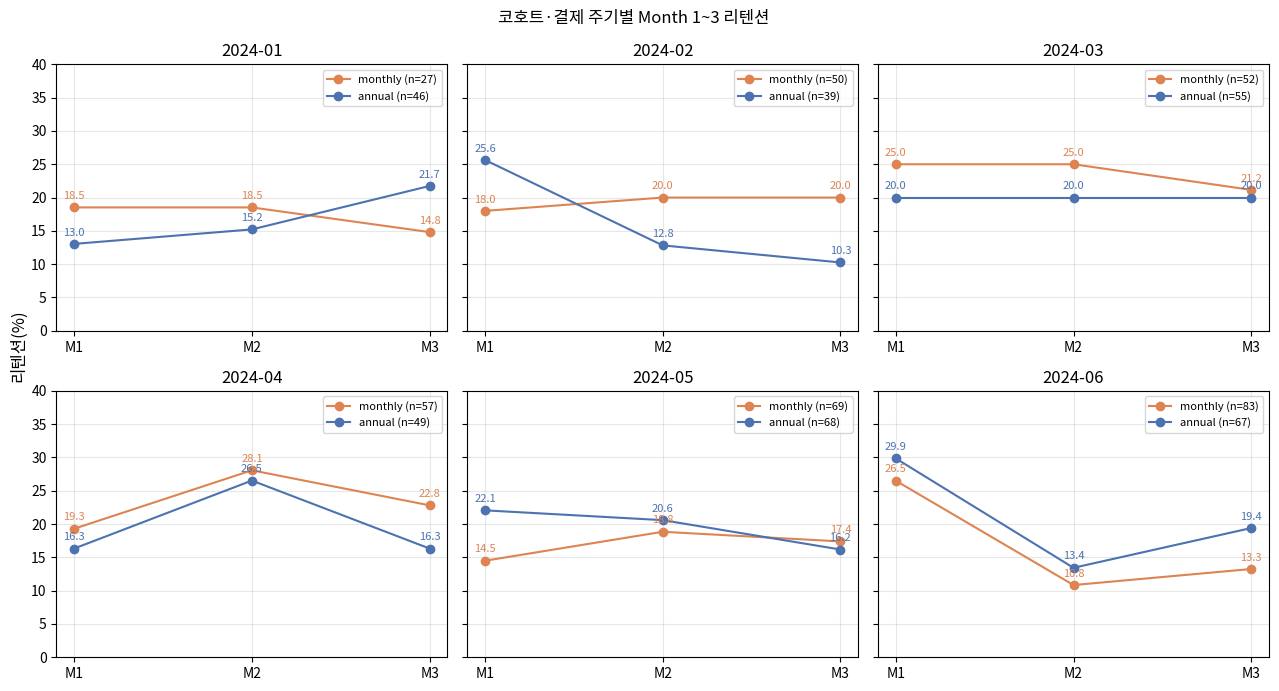

▶ 코호트별 Month 1 리텐션과 결제 주기 간 차이


billing_frequency,annual,monthly,lower,gap_%p
cohort_month,,,,
2024-01,13.04,18.52,annual,5.48
2024-02,25.64,18.00,monthly,7.64
2024-03,20.00,25.00,annual,5.00
2024-04,16.33,19.30,annual,2.97
2024-05,22.06,14.49,monthly,7.57
2024-06,29.85,26.51,monthly,3.34


▶ 경과 월별 변화폭 (±1%p 미만은 유지로 분류)


M1→M2 (%p)  M2→M3 (%p)        pattern
cohort_month billing_frequency                                       
2024-01      annual                   2.17        6.52  회복/상승 → 회복/상승
             monthly                  0.00       -3.70        유지 → 감소
2024-02      annual                 -12.82       -2.56        감소 → 감소
             monthly                  2.00        0.00     회복/상승 → 유지
2024-03      annual                   0.00        0.00        유지 → 유지
             monthly                  0.00       -3.85        유지 → 감소
2024-04      annual                  10.20      -10.20     회복/상승 → 감소
             monthly                  8.77       -5.26     회복/상승 → 감소
2024-05      annual                  -1.47       -4.41        감소 → 감소
             monthly                  4.35       -1.45     회복/상승 → 감소
2024-06      annual                 -16.42        5.97     감소 → 회복/상승
             monthly                -15.66        2.41     감소 → 회복/상승

,,cohort_subs,Month 1,Month 2,Month 3,avg_M1_3,M1→M3 (%p)
cohort_month,billing_frequency,,,,,,
2024-02,annual,39,25.64,12.82,10.26,16.24,-15.38
2024-01,annual,46,13.04,15.22,21.74,16.67,8.70
2024-06,monthly,83,26.51,10.84,13.25,16.87,-13.25
2024-05,monthly,69,14.49,18.84,17.39,16.91,2.90
2024-01,monthly,27,18.52,18.52,14.81,17.28,-3.70


In [4]:
# 1. 구독별 코호트·결제 주기 (cohort_base 재사용)
bill_base = cohort_base[['subscription_id', 'cohort_month', 'billing_frequency']]

# 2. 1~6월 코호트 선택 + Month 3 관찰 가능 여부 확인
bill_sel = bill_base[bill_base['cohort_month'].isin(sel_cohorts)].copy()
obs_check = pd.DataFrame({'cohort_month': sel_cohorts, 'month3': sel_cohorts + 3})
obs_check['observable'] = obs_check['month3'] <= last_month
print('데이터 마지막 월:', last_month); display(obs_check)

# 3. 코호트·결제 주기별 최초 구독 수와 Month 1~3 고유 재사용 구독 수
counts = bill_sel.groupby(['cohort_month', 'billing_frequency'])['subscription_id'].nunique().rename('cohort_subs').to_frame()
for k in [1, 2, 3]:
    ids_k = valid_usage.loc[valid_usage['month_index'] == k, 'subscription_id'].unique()  # 같은 달 여러 번 사용해도 unique로 1회
    counts[f'M{k}_subs'] = (bill_sel[bill_sel['subscription_id'].isin(ids_k)]
                            .groupby(['cohort_month', 'billing_frequency'])['subscription_id'].nunique())
counts = counts.fillna(0).astype(int)
display(counts)

# 4~5. billing_retention (분모 = 최초 구독 수 고정)
billing_retention = pd.DataFrame(index=counts.index)
for k in [1, 2, 3]:
    billing_retention[f'Month {k}'] = counts[f'M{k}_subs'] / counts['cohort_subs']
    # 관찰 불가 월은 NaN (0으로 처리하지 않음)
    unobs = [c + k > last_month for c in billing_retention.index.get_level_values('cohort_month')]
    billing_retention.loc[unobs, f'Month {k}'] = float('nan')
display((billing_retention * 100).round(2).style.format('{:.2f}%'))

# 6. 코호트별 선그래프
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey=True)
colors = {'monthly': '#DD8452', 'annual': '#4C72B0'}
for ax, cm in zip(axes.flat, sel_cohorts):
    for bf in ['monthly', 'annual']:
        row = billing_retention.loc[(cm, bf)] * 100
        n = counts.loc[(cm, bf), 'cohort_subs']
        ax.plot([1, 2, 3], row.values, marker='o', color=colors[bf], label=f'{bf} (n={n})')
        for x, y in zip([1, 2, 3], row.values):
            ax.annotate(f'{y:.1f}', (x, y), textcoords='offset points', xytext=(0, 6), ha='center', fontsize=8, color=colors[bf])
    ax.set_title(str(cm)); ax.set_xticks([1, 2, 3]); ax.set_xticklabels(['M1', 'M2', 'M3'])
    ax.set_ylim(0, 40); ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.supylabel('리텐션(%)'); fig.suptitle('코호트·결제 주기별 Month 1~3 리텐션')
plt.tight_layout(); plt.show()

# 7. 차이와 변화폭 (%p)
br = billing_retention * 100
m1_gap = br['Month 1'].unstack('billing_frequency')
m1_gap['lower'] = m1_gap[['monthly', 'annual']].idxmin(axis=1)
m1_gap['gap_%p'] = (m1_gap['monthly'] - m1_gap['annual']).abs().round(2)
print('▶ 코호트별 Month 1 리텐션과 결제 주기 간 차이'); display(m1_gap.round(2))

change = pd.DataFrame({
    'M1→M2 (%p)': (br['Month 2'] - br['Month 1']).round(2),
    'M2→M3 (%p)': (br['Month 3'] - br['Month 2']).round(2),
})
def pattern(r, tol=1.0):
    lab = lambda d: '유지' if abs(d) < tol else ('감소' if d < 0 else '회복/상승')
    return f"{lab(r.iloc[0])} → {lab(r.iloc[1])}"
change['pattern'] = change.apply(pattern, axis=1)
print('▶ 경과 월별 변화폭 (±1%p 미만은 유지로 분류)'); display(change)

# 8. 우선 점검 후보: Month 1~3 평균 리텐션이 낮은 조합 + 규모
summary = counts[['cohort_subs']].join(br.round(2))
summary['avg_M1_3'] = br.mean(axis=1).round(2)
summary['M1→M3 (%p)'] = (br['Month 3'] - br['Month 1']).round(2)
display(summary.sort_values('avg_M1_3').head(5))

### 과제 1 답변 작성란

**관찰 가능 여부**: 데이터의 마지막 월은 2024-12이고, 가장 늦은 2024-06 코호트의 Month 3는 2024-09이므로 **6개 코호트 모두 Month 3까지 관찰 가능**합니다. 코드에는 관찰할 수 없는 월을 0이 아닌 NaN으로 두는 처리를 넣어 두었습니다.

**우선 점검 대상: 2024-02 코호트 × annual(연간 결제)** (n=39)
- **수치 근거**: Month 1 25.64% → Month 2 12.82% (−12.82%p) → Month 3 10.26% (−2.56%p)로, **두 구간 모두 감소한 유일한 조합**입니다. Month 1~3 평균 리텐션(16.24%)과 Month 3 리텐션(10.26%)도 12개 조합 중 가장 낮습니다. 같은 코호트의 monthly는 18.0% → 20.0% → 20.0%로 유지되어, Month 3 기준 결제 주기 간 차이가 약 9.7%p로 벌어집니다.
- **가능한 원인 가설** (검증 전 가설입니다): 연간 결제는 1년 치를 미리 결제하기 때문에 사용 여부와 관계없이 계약이 유지됩니다. 그래서 도입 초기 설정이 끝난 뒤 담당자 외 팀원에게 사용이 퍼지지 않아 활동이 줄었을 *가능성*이 있습니다.
- **개선 방향**: 연간 계약 고객에게 2~3개월차에 CSM 체크인을 하고, 사용량이 줄면 알림을 보내고, 팀원 초대·활용 사례를 담은 "2차 온보딩"을 진행합니다. 이렇게 하면 갱신 시점 전에 활성도를 회복시킬 수 있습니다.
- **보조 관찰**: 2024-06 코호트는 두 결제 주기 모두 Month 1→2에 약 −16%p 급락했습니다(annual −16.42, monthly −15.66). 결제 주기와 상관없이 나타난 현상이므로 **코호트 공통 요인**(해당 시기의 유입 채널, 제품 변경, 계절성 등)을 따로 점검할 필요가 있습니다.

- **Q1.** 코호트별로 Month 1이 더 낮은 결제 주기와 차이는 다음과 같습니다.
  - 2024-01: **annual** (13.04% vs 18.52%, 5.48%p)
  - 2024-02: **monthly** (18.00% vs 25.64%, 7.64%p)
  - 2024-03: **annual** (20.00% vs 25.00%, 5.00%p)
  - 2024-04: **annual** (16.33% vs 19.30%, 2.97%p)
  - 2024-05: **monthly** (14.49% vs 22.06%, 7.57%p)
  - 2024-06: **monthly** (26.51% vs 29.85%, 3.34%p)
  
  annual이 낮은 코호트 3개, monthly가 낮은 코호트 3개로 **어느 한쪽이 일관되게 낮지 않습니다.**

- **Q2.** 변화폭(M1→M2 / M2→M3, %p)과 패턴입니다.

  | 코호트 | annual | monthly |
  |---|---|---|
  | 2024-01 | +2.17 / +6.52 (상승 지속) | 0.00 / −3.70 (유지 → 감소) |
  | 2024-02 | −12.82 / −2.56 (**연속 감소**) | +2.00 / 0.00 (소폭 상승 → 유지) |
  | 2024-03 | 0.00 / 0.00 (완전 유지) | 0.00 / −3.85 (유지 → 감소) |
  | 2024-04 | +10.20 / −10.20 (상승 → 원위치) | +8.77 / −5.26 (상승 → 감소) |
  | 2024-05 | −1.47 / −4.41 (완만한 감소) | +4.35 / −1.45 (상승 → 소폭 감소) |
  | 2024-06 | −16.42 / +5.97 (급락 → 일부 회복) | −15.66 / +2.41 (급락 → 소폭 회복) |

  첫 달 이후 곧바로 떨어지는 전형적인 감소 곡선보다는, **10~25% 구간에서 오르내리는 패턴**이 많습니다. "정확히 N개월 뒤" 기준이라 쉬었다가 돌아오는 구독이 반영되기 때문입니다. 뚜렷한 연속 감소는 2024-02 annual, 공통 급락은 2024-06 코호트에서 나타났습니다. 다만 각 칸의 분모가 27~83개라서 구독 1개 차이가 1.2~3.7%p를 움직인다는 점을 감안해야 합니다.

- **Q3.** 위의 **2024-02 × annual**입니다. 근거는 유일한 연속 감소(−12.82%p, −2.56%p), 가장 낮은 Month 3 리텐션(10.26%)과 평균 리텐션(16.24%), 같은 코호트 monthly와의 격차 확대(약 9.7%p)입니다. 가설은 연간 선결제 이후 사용 동기가 약해졌을 가능성이고, 개선 방향은 2~3개월차 CSM 체크인과 2차 온보딩입니다. 단, n=39로 작아서 확정적 결론이 아니라 **우선 들여다볼 후보**로 제시합니다.

- **Q4.** 판단할 수 없습니다. ① 코호트마다 더 낮은 쪽이 바뀌어 일관된 방향이 없고, ② 표본이 작아 차이가 통계적으로 유의한지 알 수 없으며, ③ 결제 주기는 고객이 선택한 속성이라 요금제·좌석 수·조직 규모·예산 같은 교란 변수와 얽혀 있습니다. ④ 게다가 유효 사용 필터로 원본 기록의 약 77%가 빠졌다는 데이터 품질 한계도 있습니다. 추가로 확인할 데이터는 다음과 같습니다.
  - 요금제·좌석 수·MRR을 통제한 결제 주기별 리텐션
  - 두 그룹의 기능 사용 강도·기능 종류·오류 수
  - 계정 속성(`accounts`의 산업·국가·유입 채널)
  - 해당 코호트 시기의 제품 변경·마케팅 이벤트
  - 지원 티켓·이탈 사유 데이터
  - 리텐션 차이의 통계 검정(카이제곱 등) 또는 온보딩 개입 A/B 테스트

---

## 실습 마무리

아래 질문에 답하세요.

1. 이번 분석에서는 어떤 행동을 코호트의 출발점으로 사용했나요?
2. 월간 N개월 리텐션은 어떻게 계산했나요?
3. 코호트와 세그먼트를 함께 분석하면 어떤 장점이 있나요?
4. 어떤 세그먼트의 Month 1 리텐션이 상대적으로 낮았나요?
5. 리텐션 차이와 실제 원인을 왜 구분해야 하나요?

### 실습 마무리 답변

1. **코호트 출발점**: 구독 기간 안에서 발생한 **첫 유효 기능 사용 월**입니다(가입일·구독 시작일이 아님).
2. **N개월 리텐션 계산**: (코호트 월로부터 정확히 N개월 뒤에 기능을 사용한 고유 구독 수) ÷ (코호트 최초 구독 수). 분모는 모든 N에서 고정했고, 중간 달에 쉬었다 돌아온 구독도 포함했습니다.
3. **코호트 × 세그먼트의 장점**: 시기에 따른 효과(코호트)와 고객 특성에 따른 효과(세그먼트)를 분리해서 볼 수 있습니다. 예를 들어 2024-06 급락은 결제 주기와 무관한 코호트 공통 현상이고, 2024-02 annual 하락은 그 코호트 안에서도 특정 세그먼트에 한정된 현상임을 구분할 수 있습니다.
4. **Month 1이 낮은 세그먼트**: 요금제 중에서는 **Basic (18.8%)**입니다. 결제 주기는 코호트마다 방향이 달랐습니다(annual 3회, monthly 3회 더 낮음).
5. **차이와 원인을 구분해야 하는 이유**: 리텐션 차이는 관찰된 결과일 뿐이고, 표본 크기에 따른 우연, 세그먼트 간 교란 변수, 데이터 품질 문제 때문에 생길 수도 있습니다. 원인을 단정하고 대응하면 엉뚱한 곳에 자원을 쓰게 됩니다. 그래서 차이로 점검 대상을 좁히고 → 가설을 세우고 → 추가 데이터나 실험으로 검증해야 합니다.